# 08 – Predictive Analysis (Classification)

**Goal:** predict whether the Falcon 9 first stage will land (`Class` = 1) or not (`Class` = 0).

**Steps**
1. Load features (`dataset_part_3.csv`) and labels (`Class` from `dataset_part_2.csv`).
2. Split into train (80%) and test (20%) sets with `random_state=2`.
3. Standardize the features.
4. Tune 4 models with `GridSearchCV(cv=10)`: Logistic Regression, SVM, Decision Tree, KNN.
5. Compare validation accuracy, test accuracy and confusion matrices.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

IMG = "../images/"
sns.set_theme(style="whitegrid", font_scale=1.2)

data = pd.read_csv("../data/dataset_part_2.csv")
X = pd.read_csv("../data/dataset_part_3.csv")
Y = data["Class"].to_numpy()
print("X:", X.shape, "| Y:", Y.shape, "| landed:", Y.sum(), "| not landed:", (Y == 0).sum())

X: (90, 80) | Y: (90,) | landed: 60 | not landed: 30


## 1. Train / test split and standardization

In [2]:
X_train_raw, X_test_raw, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

# fit the scaler on the training data only, then use it on both sets
transform = preprocessing.StandardScaler().fit(X_train_raw)
X_train = transform.transform(X_train_raw)
X_test = transform.transform(X_test_raw)

print("train samples:", X_train.shape[0], "| test samples:", X_test.shape[0])
print("test set: landed =", Y_test.sum(), "| not landed =", (Y_test == 0).sum())

train samples: 72 | test samples: 18
test set: landed = 12 | not landed = 6


## 2. Hyper-parameter search for each model (GridSearchCV, cv=10)

In [3]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000),
        {"C": [0.01, 0.1, 1], "solver": ["lbfgs"]}),          # penalty is L2 by default
    "SVM": (SVC(),
        {"kernel": ["linear", "rbf", "poly", "sigmoid"], "C": np.logspace(-3, 3, 5), "gamma": np.logspace(-3, 3, 5)}),
    "Decision Tree": (DecisionTreeClassifier(random_state=2),
        {"criterion": ["gini", "entropy"], "splitter": ["best", "random"], "max_depth": [2 * n for n in range(1, 10)],
         "max_features": ["sqrt", "log2"], "min_samples_leaf": [1, 2, 4], "min_samples_split": [2, 5, 10]}),
    "KNN": (KNeighborsClassifier(),
        {"n_neighbors": list(range(1, 11)), "algorithm": ["auto", "ball_tree", "kd_tree", "brute"], "p": [1, 2]}),
}

results, fitted = [], {}
for name, (model, params) in models.items():
    search = GridSearchCV(model, params, cv=10, scoring="accuracy")
    search.fit(X_train, Y_train)
    fitted[name] = search
    results.append({"Model": name,
                    "Best parameters": search.best_params_,
                    "Validation accuracy": search.best_score_,
                    "Test accuracy": search.score(X_test, Y_test)})
    print(f"{name:20s} val={search.best_score_:.4f}  test={search.score(X_test, Y_test):.4f}  {search.best_params_}")

results_df = pd.DataFrame(results)

Logistic Regression  val=0.8196  test=0.8333  {'C': 0.1, 'solver': 'lbfgs'}


SVM                  val=0.8482  test=0.8333  {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}


Decision Tree        val=0.8339  test=0.7222  {'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}


KNN                  val=0.8196  test=0.8333  {'algorithm': 'auto', 'n_neighbors': 7, 'p': 1}


In [4]:
results_df[["Model", "Validation accuracy", "Test accuracy"]].round(4)

,Model,Validation accuracy,Test accuracy
0,Logistic Regression,0.8196,0.8333
1,SVM,0.8482,0.8333
2,Decision Tree,0.8339,0.7222
3,KNN,0.8196,0.8333


## 3. Confusion matrices

Logistic Regression  TN=3 FP=3 FN=0 TP=12
SVM                  TN=3 FP=3 FN=0 TP=12


Decision Tree        TN=3 FP=3 FN=2 TP=10
KNN                  TN=3 FP=3 FN=0 TP=12


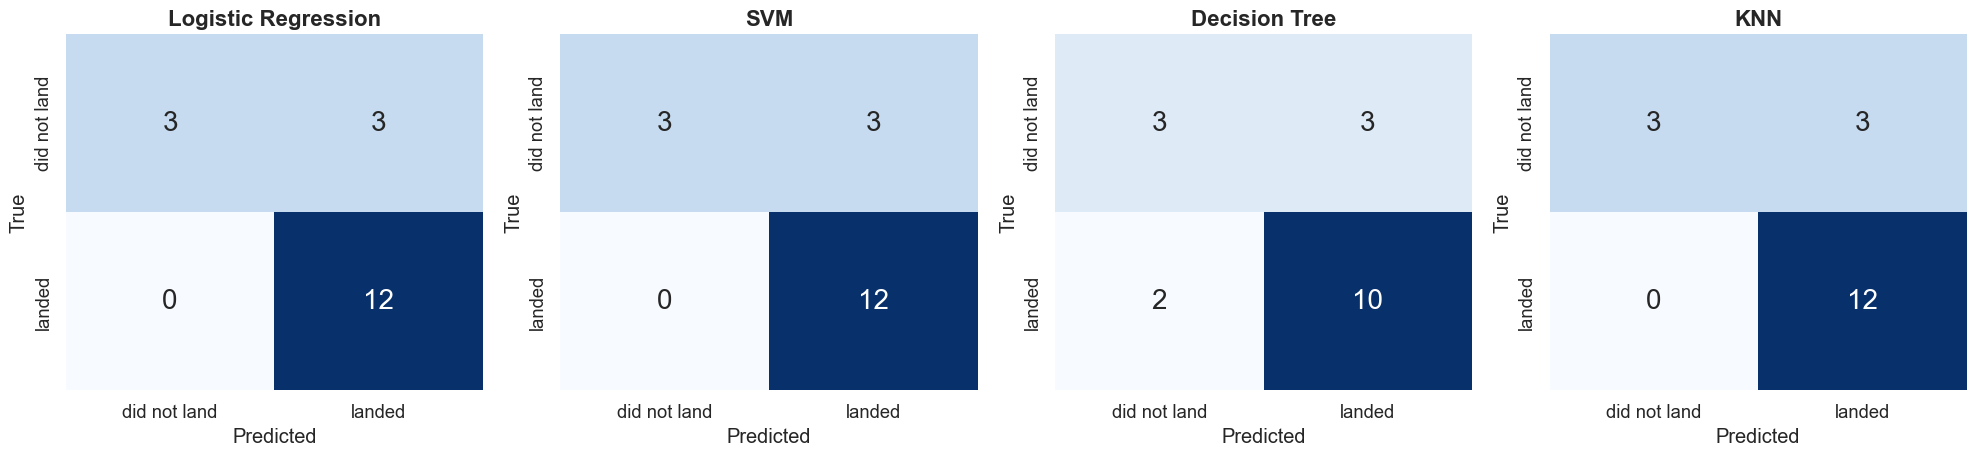

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for ax, (name, search) in zip(axes, fitted.items()):
    cm = confusion_matrix(Y_test, search.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 20},
                xticklabels=["did not land", "landed"], yticklabels=["did not land", "landed"])
    ax.set_title(name, fontsize=16, weight="bold"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    tn, fp, fn, tp = cm.ravel()
    print(f"{name:20s} TN={tn} FP={fp} FN={fn} TP={tp}")
plt.tight_layout()
fig.savefig(IMG + "ml_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Compare the models

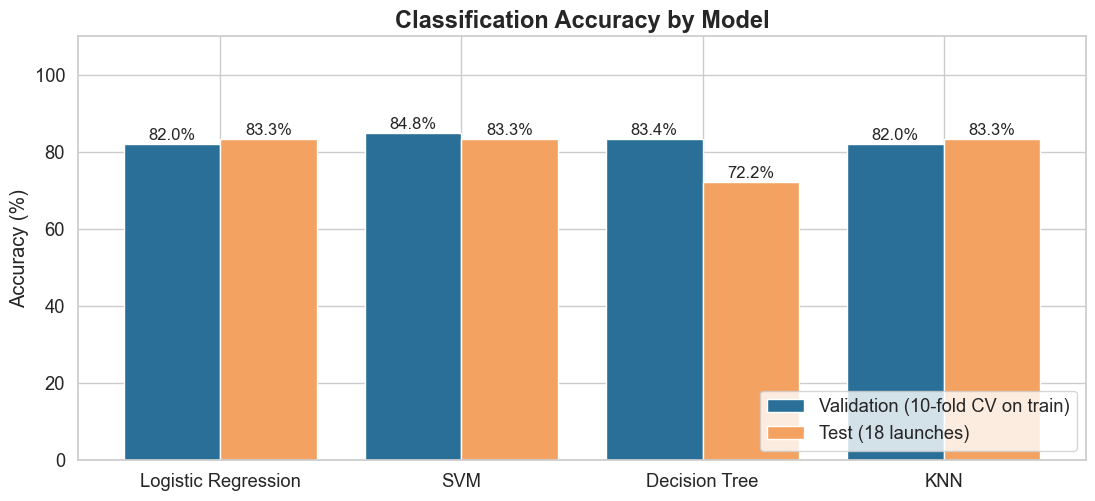

In [6]:
fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(results_df))
b1 = ax.bar(x - 0.2, results_df["Validation accuracy"] * 100, 0.4, label="Validation (10-fold CV on train)", color="#2a6f97")
b2 = ax.bar(x + 0.2, results_df["Test accuracy"] * 100, 0.4, label="Test (18 launches)", color="#f4a261")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{b.get_height():.1f}%", ha="center", fontsize=12)
ax.set_xticks(x); ax.set_xticklabels(results_df["Model"])
ax.set_ylim(0, 110); ax.set_ylabel("Accuracy (%)"); ax.legend(loc="lower right")
ax.set_title("Classification Accuracy by Model", fontsize=17, weight="bold")
fig.savefig(IMG + "ml_accuracy_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Is the test set big enough to pick a winner?
The test set has only **18 launches**, so one wrong prediction changes accuracy by 5.6 points.
To get a fairer picture we also run **10-fold stratified cross-validation on all 90 launches** with each model's best parameters
(scaling inside each fold).

In [7]:
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=2)
cv_rows = []
for name, search in fitted.items():
    model = make_pipeline(preprocessing.StandardScaler(), search.best_estimator_)
    scores = cross_val_score(model, X, Y, cv=cv, scoring="accuracy")
    cv_rows.append({"Model": name, "CV mean accuracy": scores.mean(), "CV std": scores.std()})
cv_df = pd.DataFrame(cv_rows)
print(cv_df.round(4).to_string(index=False))

              Model  CV mean accuracy  CV std
Logistic Regression            0.8333  0.1242
                SVM            0.8444  0.1018
      Decision Tree            0.7889  0.1356
                KNN            0.8111  0.0868


## 6. What drives landing success?
Many `Class = 0` launches are missions where SpaceX **did not even try** to land (outcome `None ...`).
We split the failures into "no attempt" and "attempt failed", and look at booster Block and reuse.

In [8]:
attempted = data["Outcome"].str.startswith(("True", "False"))
print("launches with Class 0:", (Y == 0).sum())
print("  no landing attempt :", (~attempted).sum())
print("  attempt but failed :", (attempted & (data["Class"] == 0)).sum())
print(f"success rate when a landing was attempted: {data[attempted]['Class'].mean():.1%} ({data[attempted]['Class'].sum()} of {attempted.sum()})")
print()
print("Success rate by Block (all launches vs. attempted landings only):")
by_block = pd.DataFrame({
    "all launches": data.groupby("Block")["Class"].mean(),
    "attempted only": data[attempted].groupby("Block")["Class"].mean(),
    "n (all)": data.groupby("Block")["Class"].count()})
print(by_block.round(3))
print()
no_try = data[~attempted]
print("Launches with no landing attempt – by orbit:", no_try["Orbit"].value_counts().to_dict())
print("Launches with no landing attempt – by year:", pd.to_datetime(no_try["Date"]).dt.year.value_counts().sort_index().to_dict())
print()
print("Reused booster vs. new booster:")
print(data.groupby("Reused")["Class"].agg(launches="count", rate="mean").round(3))

launches with Class 0: 30
  no landing attempt : 21
  attempt but failed : 9
success rate when a landing was attempted: 87.0% (60 of 69)

Success rate by Block (all launches vs. attempted landings only):
       all launches  attempted only  n (all)
Block                                       
1.0           0.211           0.400       19
2.0           1.000           1.000        6
3.0           0.733           1.000       15
4.0           0.545           1.000       11
5.0           0.846           0.917       39

Launches with no landing attempt – by orbit: {'GTO': 12, 'ISS': 4, 'LEO': 2, 'PO': 1, 'MEO': 1, 'SO': 1}
Launches with no landing attempt – by year: {2010: 1, 2012: 1, 2013: 2, 2014: 3, 2015: 2, 2016: 1, 2017: 3, 2018: 6, 2019: 1, 2020: 1}

Reused booster vs. new booster:
        launches   rate
Reused                 
False         53  0.585
True          37  0.784


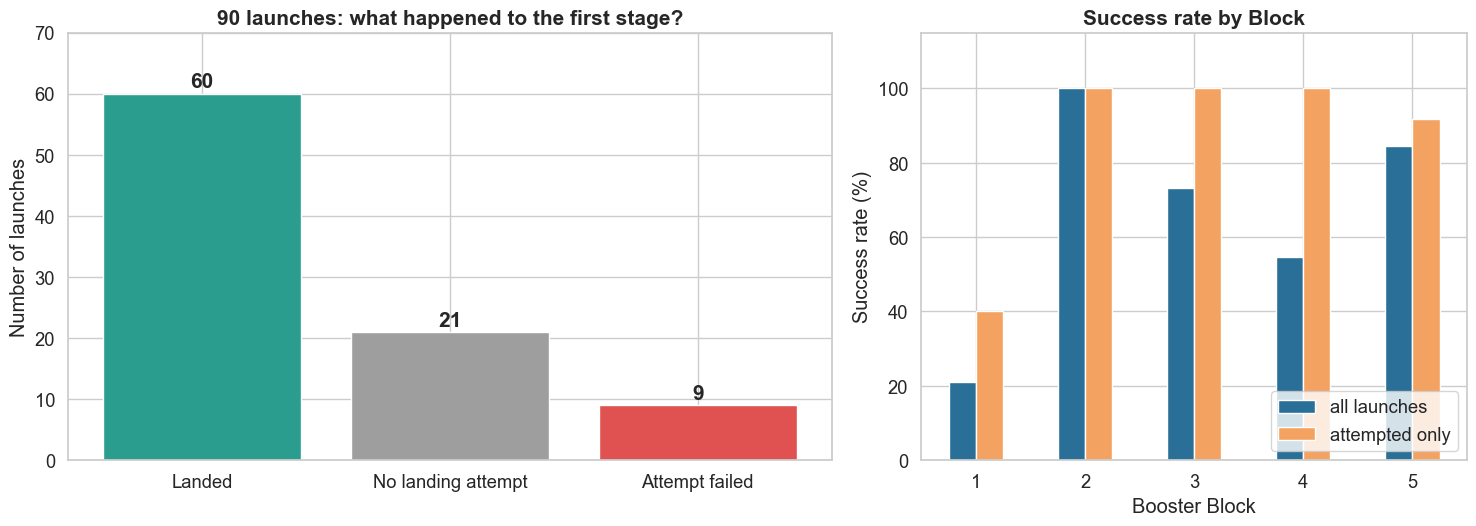

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
# left: why did Class = 0 happen?
parts = pd.Series({"Landed": int(data["Class"].sum()),
                   "No landing attempt": int((~attempted).sum()),
                   "Attempt failed": int((attempted & (data["Class"] == 0)).sum())})
axes[0].bar(parts.index, parts.values, color=["#2a9d8f", "#9e9e9e", "#e05252"])
for i, v in enumerate(parts.values):
    axes[0].text(i, v + 1, str(v), ha="center", fontsize=15, weight="bold")
axes[0].set_ylim(0, 70); axes[0].set_ylabel("Number of launches")
axes[0].set_title("90 launches: what happened to the first stage?", fontsize=15, weight="bold")
# right: success rate by Block, all launches vs. attempted landings only
by_block[["all launches", "attempted only"]].mul(100).plot.bar(ax=axes[1], color=["#2a6f97", "#f4a261"], rot=0)
axes[1].set_ylim(0, 115); axes[1].set_ylabel("Success rate (%)"); axes[1].set_xlabel("Booster Block")
axes[1].set_xticklabels([str(int(b)) for b in by_block.index])
axes[1].set_title("Success rate by Block", fontsize=15, weight="bold"); axes[1].legend(loc="lower right")
plt.tight_layout()
fig.savefig(IMG + "ml_landing_drivers.png", dpi=200, bbox_inches="tight")
plt.show()